# RQ2：下游出发延误预测与解释

研究问题：上游飞机实际到达后，能否预测下游出发延误？本页依据本轮配置、模型 manifest 与实际指标解释结果，不重新训练，也不预设使用哪一组特征或算法。

In [1]:
ROOT = __import__('pathlib').Path.cwd()
RUN_DIR = ROOT / 'experiments/runs/R0012'

In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

if "ROOT" not in globals():
    ROOT = Path.cwd()
    while not (ROOT / "scripts/build_features.py").exists():
        if ROOT.parent == ROOT:
            raise RuntimeError("请在 Airline-delay 仓库中运行 Notebook")
        ROOT = ROOT.parent
if "RUN_DIR" not in globals():
    candidates = [p for p in (ROOT / "experiments/runs").glob("R*")
                  if (p / "metrics.csv").exists() and (p / "model_manifest.json").exists()]
    if not candidates:
        raise RuntimeError("请先归档预测实验，或手动设置 RUN_DIR")
    RUN_DIR = max(candidates, key=lambda p: int(p.name[1:]))
TABLES = RUN_DIR / "tables"
FIGURES = RUN_DIR / "figures"
def table(name):
    return pd.read_csv(TABLES / name)
def figure(name):
    display(Image(filename=str(FIGURES / name)))
def receipt(name):
    return json.loads((RUN_DIR / name).read_text(encoding="utf-8"))
display(Markdown(f"**归档运行：{RUN_DIR.name}**。本 Notebook 读取该轮表格与图，不重新拟合模型。"))

**归档运行：R0012**。本 Notebook 读取该轮表格与图，不重新拟合模型。

In [3]:
config = receipt("config.json") if (RUN_DIR / "config.json").exists() else {}
model_manifest = receipt("model_manifest.json")
features = model_manifest.get("features", config.get("features", []))
group_name = model_manifest.get("feature_group", config.get("feature_group", "未登记"))
models = model_manifest.get("models", [])
display(Markdown(f"本轮信息组：**{group_name}**；阶段：**{config.get('stage', '未登记')}**；模型：**{', '.join(models)}**。"))
display(pd.DataFrame([{"development_only": model_manifest.get("development_only"),
                       "parent_run_id": config.get("parent_run_id"),
                       "change": config.get("change"), "include_baselines": model_manifest.get("include_baselines")}]))

本轮信息组：**G3**；阶段：**P3**；模型：**training_mean, training_median, carry_forward, g3_linear**。

,development_only,parent_run_id,change,include_baselines
0,True,R0009,Add historical airport departures and upcoming...,True


## 1. 时间折与成熟标签

开发使用 4→5、4–5→6、4–6→7 月 UTC 前向验证。训练预测时点及标签时点均须严格早于训练截止；最终测试只能在规则冻结后进行。下表记录本轮实际切分和评估 ID 哈希。

In [4]:
display(pd.read_csv(RUN_DIR / "split_audit.csv"))
display(pd.DataFrame([{key: model_manifest.get(key) for key in ["evaluation_rows", "evaluation_ids_sha256", "split_sha256", "development_only"]}]))

,fold,train_start,train_end_exclusive,validation_start,validation_end_exclusive,train_rows,validation_rows,excluded_immature_training_labels,max_train_prediction_time,max_train_label_time,min_validation_prediction_time,max_validation_prediction_time,train_id_sha256,validation_id_sha256,train_target_sha256,validation_target_sha256
0,2026-05,2026-04-01T00:00:00+00:00,2026-05-01T00:00:00+00:00,2026-05-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,553140,574571,1544,2026-04-30T23:30:00+00:00,2026-04-30T23:59:00+00:00,2026-05-01T00:00:00+00:00,2026-05-31T23:59:00+00:00,1d9c1c54be72084a627b3865b21fc94e9e93254c332782...,db70eb2f46beff2f44a0d978cce9dbd84b44dbb52b1e50...,5c386d0f0ee1fc6a9a99cf99f6182c2d58579a493e3408...,4127ab7e0a6298fa42539db1bbc74075047d578ec63df3...
1,2026-06,2026-04-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,2026-06-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,1127717,561972,1538,2026-05-31T23:36:00+00:00,2026-05-31T23:59:00+00:00,2026-06-01T00:00:00+00:00,2026-06-30T23:59:00+00:00,a90b8697524811822601e389f6dcd6af7155f7a3d71e2a...,e96b8cf52f6698df4b45e9a05b14fa21ebb3e2bc1f61ab...,92e5c3e7e1944ae98416f68e3b23b51c470d00762f1187...,6f0f88b0e09b752f77db4007c4375cfdf7bdfbf30355f4...
2,2026-07,2026-04-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,2026-07-01T00:00:00+00:00,2026-08-01T00:00:00+00:00,1689573,570548,1654,2026-06-30T23:29:00+00:00,2026-06-30T23:59:00+00:00,2026-07-01T00:00:00+00:00,2026-07-31T23:59:00+00:00,620f6bd533a0293c182707e431ac65134e28da7eb60cc3...,df7fcbba5aaedaa4b8e9d6a590fa9bfaf19de5ff4b9070...,3f44149b050fa6f382963ad2b9afca69b645b2bb61692b...,0533c6befc1f7beac3ebae6d421b6945f82253dc78b655...


,evaluation_rows,evaluation_ids_sha256,split_sha256,development_only
0,1707091,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,True


## 2. 本轮信息、算法与预处理

实际地面周转、下游实际出发及未来运营结果不能进入特征。朴素参照包括每折训练均值、中位数，以及上游非负到达延误原样传递；仅在本轮确实归档它们时展示比较。所有数据依赖的预处理均在训练折拟合。

In [5]:
categorical = set(model_manifest.get("categorical_features", []))
display(pd.DataFrame({"字段": features, "类型": ["类别" if name in categorical else "数值" for name in features]}))
display(pd.json_normalize(model_manifest.get("effective_preprocessing", {})))
display(pd.json_normalize({key: model_manifest.get(key) for key in ["models", "model_name", "model_type", "model_params"]}))
display(Markdown("上游到达延误：" + ("**已作为预测变量加入**。" if "upstream_arr_delay_minutes" in features else "**不在本轮模型特征清单中**。")))

,字段,类型
0,airport_id,类别
1,route,类别
2,downstream_airline,类别
3,aircraft_family,类别
4,downstream_distance,数值
5,downstream_crs_elapsed_time,数值
6,downstream_day_of_week,数值
7,downstream_sched_hour,数值
8,scheduled_turnaround_minutes,数值
9,upstream_arr_delay_minutes,数值


,min_frequency,drop,sparse,categorical_imputation,numeric_imputation,numeric_scaling,unknown_categories
0,20,first,True,constant __MISSING__; keep_empty_features=True,median; add_indicator=True; keep_empty_feature...,"StandardScaler(with_mean=False), fixed across ...",infrequent_if_exist


,models,model_name,model_type,model_params.copy_X,model_params.fit_intercept,model_params.n_jobs,model_params.positive,model_params.tol
0,"[training_mean, training_median, carry_forward...",g3_linear,linear,True,True,8,False,0.000001


上游到达延误：**已作为预测变量加入**。

## 3. 各月与整体预测误差

MAE 为主要指标；RMSE 对大误差更敏感。预测统一非负截断。整体指标按全部评估行聚合绝对/平方误差，不能简单平均月折指标。是否改善还须检查评估 ID、切分和目标一致。

,model,fold,n,mae,rmse,target_ge15_share
0,training_mean,2026-05,574571,17.969705,43.443239,0.207785
411,training_median,2026-05,574571,13.209259,45.383891,0.207785
822,carry_forward,2026-05,574571,14.173169,49.267137,0.207785
1233,g3_linear,2026-05,574571,14.783665,40.398414,0.207785
1644,training_mean,2026-06,561972,21.068890,50.817858,0.247952
2059,training_median,2026-06,561972,16.995806,53.396380,0.247952
2474,carry_forward,2026-06,561972,17.543874,56.830990,0.247952
2889,g3_linear,2026-06,561972,17.361479,46.496505,0.247952
3304,training_mean,2026-07,570548,23.718273,57.589119,0.272265
3720,training_median,2026-07,570548,19.678702,60.592404,0.272265


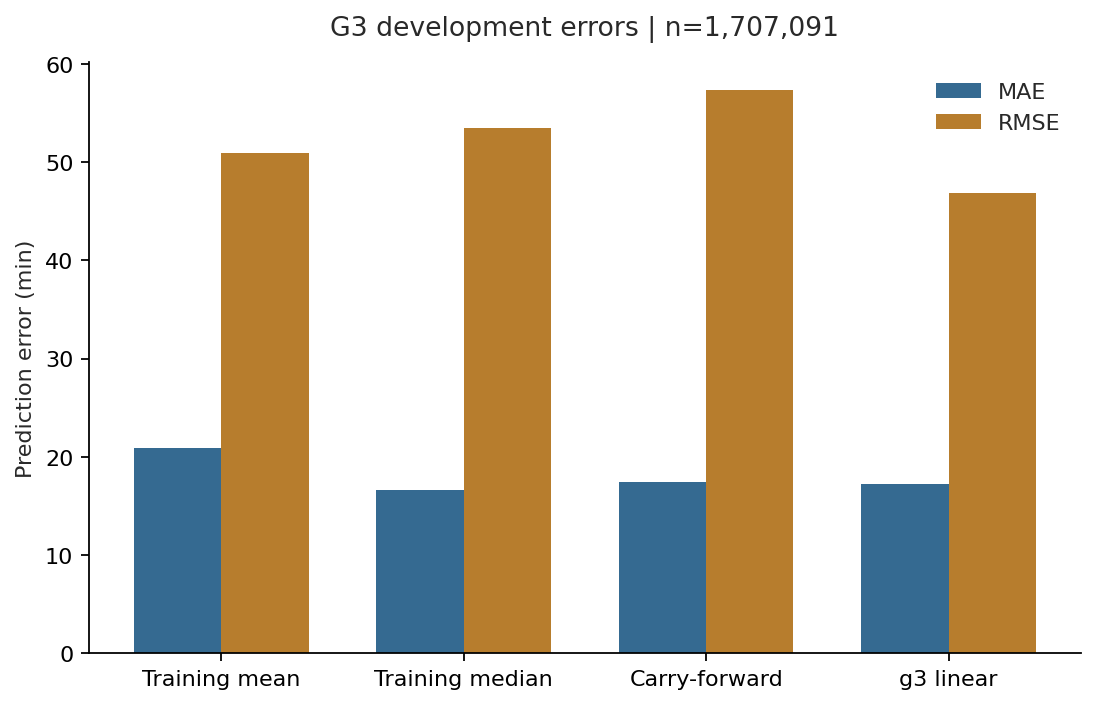

,n,mae,rmse,MAE改善_vs_training_mean_分钟,MAE改善_vs_training_median_分钟,MAE改善_vs_carry_forward_分钟
model,,,,,,
carry_forward,1707091,17.425608,57.330724,3.485645,-0.807590,0.000000
g3_linear,1707091,17.279576,46.903417,3.631676,-0.661559,0.146031
training_mean,1707091,20.911252,50.929578,0.000000,-4.293235,-3.485645
training_median,1707091,16.618017,53.468967,4.293235,0.000000,0.807590


In [6]:
metrics = pd.read_csv(RUN_DIR / "metrics.csv")
main = metrics.loc[metrics["group"].eq("all")]
columns = [name for name in ["model", "fold", "n", "mae", "rmse", "target_ge15_share"] if name in main]
display(main[columns])
if (FIGURES / "rq2_metric_comparison.png").exists():
    figure("rq2_metric_comparison.png")
pooled = main.loc[main.fold.eq("overall")].set_index("model")
comparison = pooled[["n", "mae", "rmse"]].copy()
for baseline in ["training_mean", "training_median", "carry_forward"]:
    if baseline in pooled.index:
        comparison[f"MAE改善_vs_{baseline}_分钟"] = pooled.loc[baseline, "mae"] - comparison.mae
display(comparison)
if not any(name in pooled.index for name in ["training_mean", "training_median", "carry_forward"]):
    display(Markdown("本轮未重算朴素基线。跨轮参照须使用下方已有比较文件，并确认相同评估 ID/切分。"))

## 4. 严重延误、隔夜与运行分组

普通/严重组按真实非负延误 <60 / ≥60 分钟预定义，是结果人群误差，不能用于事后挑选有利人群。各组同时列样本量；缺失或很小的组不强行解释。

In [7]:
overall = metrics.loc[metrics.fold.eq("overall")]
for group in ["severity", "overnight", "day_of_week", "scheduled_hour"]:
    display(Markdown(f"**{group}**"))
    display(overall.loc[overall["group"].eq(group), ["model", "value", "n", "mae", "rmse"]])
for group in ["airport", "airline", "aircraft_family", "aircraft_variant"]:
    grouped = overall.loc[overall["group"].eq(group)]
    for model, rows in grouped.groupby("model", sort=False):
        display(Markdown(f"**{group} / {model}（样本最多的 20 组）**"))
        display(rows[["value", "n", "mae", "rmse"]].sort_values("n", ascending=False).head(20))

**severity**

,model,value,n,mae,rmse
5385,carry_forward,ordinary_lt60,1574341,12.426625,39.098450
5386,carry_forward,severe_ge60,132750,76.710750,155.361423
5804,g3_linear,ordinary_lt60,1574341,10.752715,17.456514
5805,g3_linear,severe_ge60,132750,94.684510,157.085819
6223,training_mean,ordinary_lt60,1574341,12.547824,14.185081
6224,training_mean,severe_ge60,132750,120.096846,175.979509
6642,training_median,ordinary_lt60,1574341,6.803280,14.576591
6643,training_median,severe_ge60,132750,133.015330,185.052407


**overnight**

,model,value,n,mae,rmse
5359,carry_forward,False,1377745,13.105141,46.287583
5360,carry_forward,True,329346,35.499311,89.853296
5778,g3_linear,False,1377745,17.320114,45.886524
5779,g3_linear,True,329346,17.109996,50.937746
6197,training_mean,False,1377745,21.745577,51.909110
6198,training_mean,True,329346,17.421042,46.609275
6616,training_median,False,1377745,18.540974,54.857502
6617,training_median,True,329346,8.573761,47.219731


**day_of_week**

...

,value,n,mae,rmse
5395,Boeing 737 NG,484155,16.301860,40.044085
5388,Airbus A320 family ceo,272749,20.979075,59.187724
5401,Embraer E170/E175,247979,13.941166,40.449037
5402,NaN,202314,16.857993,47.282706
5394,Boeing 737 MAX,172586,15.124837,34.238013
5400,Bombardier CRJ,143738,21.409264,60.852003
5389,Airbus A320 family neo,80232,18.893222,49.350212
5393,Boeing 717,36493,15.387527,41.013845
5387,Airbus A220,33438,18.248353,52.111047
5396,Boeing 757,25735,19.027404,48.105158


**aircraft_family / training_mean（样本最多的 20 组）**

,value,n,mae,rmse
5814,Boeing 737 NG,484155,19.858802,43.843494
5807,Airbus A320 family ceo,272749,23.808098,63.002074
5820,Embraer E170/E175,247979,18.968041,44.034438
5821,NaN,202314,20.511528,52.069606
5813,Boeing 737 MAX,172586,18.840765,38.439706
5819,Bombardier CRJ,143738,24.579111,65.990291
5808,Airbus A320 family neo,80232,21.943663,53.708406
5812,Boeing 717,36493,20.413072,45.142297
5806,Airbus A220,33438,21.870098,55.691022
5815,Boeing 757,25735,21.385403,50.894762


**aircraft_family / training_median（样本最多的 20 组）**

,value,n,mae,rmse
6233,Boeing 737 NG,484155,16.692731,46.775717
6226,Airbus A320 family ceo,272749,19.656288,65.692253
6239,Embraer E170/E175,247979,11.913759,45.638386
6240,NaN,202314,16.382569,54.495220
6232,Boeing 737 MAX,172586,16.924443,41.808464
6238,Bombardier CRJ,143738,19.017455,68.426929
6227,Airbus A320 family neo,80232,17.299058,56.290846
6231,Boeing 717,36493,13.785849,47.256972
6225,Airbus A220,33438,16.270830,57.979452
6234,Boeing 757,25735,17.141675,53.565420


## 5. 直接前轮比较与证据

特征增量与算法差异分开比较，每轮只改变一个研究因素。只有同一评估样本、目标及切分下的差值才能作为直接改善证据。预测、模型、评估 ID 与配置保存在本轮归档；下方只显示已有比较文件，不自动重算或更改前轮结果。

In [8]:
comparison_paths = {p for folder in [RUN_DIR, TABLES] if folder.exists()
                    for pattern in ["*comparison*.csv", "*parent*.csv", "*comparison*.json", "*parent*.json"]
                    for p in folder.glob(pattern)}
for key in ["parent_comparison_path", "comparison_path", "parent_comparison_file"]:
    value = config.get(key)
    if isinstance(value, str):
        candidate = Path(value)
        for path in ([candidate] if candidate.is_absolute() else [RUN_DIR / candidate, ROOT / candidate]):
            if path.is_file():
                comparison_paths.add(path)
for path in sorted(comparison_paths):
    display(Markdown(f"**{path.name}**"))
    display(pd.read_csv(path) if path.suffix == ".csv" else pd.json_normalize(json.loads(path.read_text(encoding="utf-8"))))
if not comparison_paths:
    display(Markdown("本轮尚无单独前轮比较文件；不从不同样本的指标直接推断增益。"))

本轮尚无单独前轮比较文件；不从不同样本的指标直接推断增益。